In [2]:
from sklearn.model_selection import train_test_split
import inspect
print(inspect.getsource(train_test_split))

@validate_params(
    {
        "test_size": [
            Interval(RealNotInt, 0, 1, closed="neither"),
            Interval(numbers.Integral, 1, None, closed="left"),
            None,
        ],
        "train_size": [
            Interval(RealNotInt, 0, 1, closed="neither"),
            Interval(numbers.Integral, 1, None, closed="left"),
            None,
        ],
        "random_state": ["random_state"],
        "shuffle": ["boolean"],
        "stratify": ["array-like", None],
    },
    prefer_skip_nested_validation=True,
)
def train_test_split(
    *arrays,
    test_size=None,
    train_size=None,
    random_state=None,
    shuffle=True,
    stratify=None,
):
    """Split arrays or matrices into random train and test subsets.

    Quick utility that wraps input validation,
    ``next(ShuffleSplit().split(X, y))``, and application to input data
    into a single call for splitting (and optionally subsampling) data into a
    one-liner.

    Read more in the :ref:`User Guide <cr

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report

LOAD THE DATASET 

In [5]:
df = pd.read_csv("spam.csv", encoding="latin-1")


In [6]:
import pandas as pd 
df = pd.read_csv("spam.csv", encoding="latin-1")
df = df.iloc[:, :2]
df.columns = ["label", "message"]
df["label"] = df["label"].map({"ham": 0, "spam": 1})
print(df.head())
print("\nColumns:", df.columns)

   label                                            message
0      0  Go until jurong point, crazy.. Available only ...
1      0                      Ok lar... Joking wif u oni...
2      1  Free entry in 2 a wkly comp to win FA Cup fina...
3      0  U dun say so early hor... U c already then say...
4      0  Nah I don't think he goes to usf, he lives aro...

Columns: Index(['label', 'message'], dtype='object')


In [6]:
df = df[['v1', 'v2']]
df = df.rename(columns={
    'v1': 'label',
    'v2': 'message'
})
df['label'] = df['label'].map({
    'ham': 0,
    'spam': 1
})
print(df.head())
print(df.columns)

   label                                            message
0      0  Go until jurong point, crazy.. Available only ...
1      0                      Ok lar... Joking wif u oni...
2      1  Free entry in 2 a wkly comp to win FA Cup fina...
3      0  U dun say so early hor... U c already then say...
4      0  Nah I don't think he goes to usf, he lives aro...
Index(['label', 'message'], dtype='object')


In [7]:
vectorizer = TfidfVectorizer()

In [10]:
from sklearn.model_selection import train_test_split

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['message'],
    df['label'],
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)

In [11]:
X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

In [12]:
print("\nTF-IDF training shape:", X_train.shape)
print("TF-IDF testing shape:", X_test.shape)


TF-IDF training shape: (4457, 7701)
TF-IDF testing shape: (1115, 7701)


In [13]:
import numpy as np
y_train_binary = np.where(y_train == "spam", 1, 0)
y_test_binary = np.where(y_test == "spam", 1, 0)
def manual_perceptron(X, y, learning_rate=0.01, epochs=1000):
    weights = np.zeros(X.shape[1])
    bias = 0
    for epoch in range(epochs):
        errors = 0
        for i in range(X.shape[0]):
            x_i = X[i].toarray().ravel()
            z = np.dot(x_i, weights) + bias
            prediction = 1 if z >= 0 else 0
            error = y[i] - prediction
            if error != 0:
                weights += learning_rate * error * x_i
                bias += learning_rate * error
                errors += 1
        if errors == 0:
            break
    return weights, bias, epoch + 1
weights, bias, epochs_used = manual_perceptron(
    X_train,
    y_train_binary,
    learning_rate=0.01,
    epochs=1000
)
print("Epochs used:", epochs_used)

Epochs used: 2


In [14]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (4457, 7701)
y_train: (4457,)
X_test: (1115, 7701)
y_test: (1115,)


In [15]:
def predict_perceptron(X, weights, bias):
    predictions = []
    for i in range(X.shape[0]):
        x_i = X[i].toarray().ravel()
        z = np.dot(x_i, weights) + bias
        prediction = 1 if z >= 0 else 0
        predictions.append(prediction)
    return np.array(predictions)
y_pred = predict_perceptron(X_test, weights, bias)

In [19]:
accuracy = accuracy_score(y_test_binary, y_pred)
print("\nAccuracy:", accuracy)
print("\nClassification Report:")
print(classification_report(y_test_binary, y_pred))


Accuracy: 0.9820627802690582

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       966
           1       0.96      0.91      0.93       149

    accuracy                           0.98      1115
   macro avg       0.97      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



In [16]:

new_message = ["Congratulations! You won a free prize."]
new_message_tfidf = vectorizer.transform(new_message)
prediction = predict_perceptron(
    new_message_tfidf,
    weights,
    bias
)
label = "spam" if prediction[0] == 1 else "ham"
print("\nNew message:", new_message[0])
print("Prediction:", label)


New message: Congratulations! You won a free prize.
Prediction: ham


In [17]:
from sklearn.decomposition import TruncatedSVD
import matplotlib.pyplot as plt
svd = TruncatedSVD(n_components=2, random_state=42)
X_2D = svd.fit_transform(X_train)
print("Original shape:", X_train.shape)
print("2D shape:", X_2D.shape)

Original shape: (4457, 7701)
2D shape: (4457, 2)


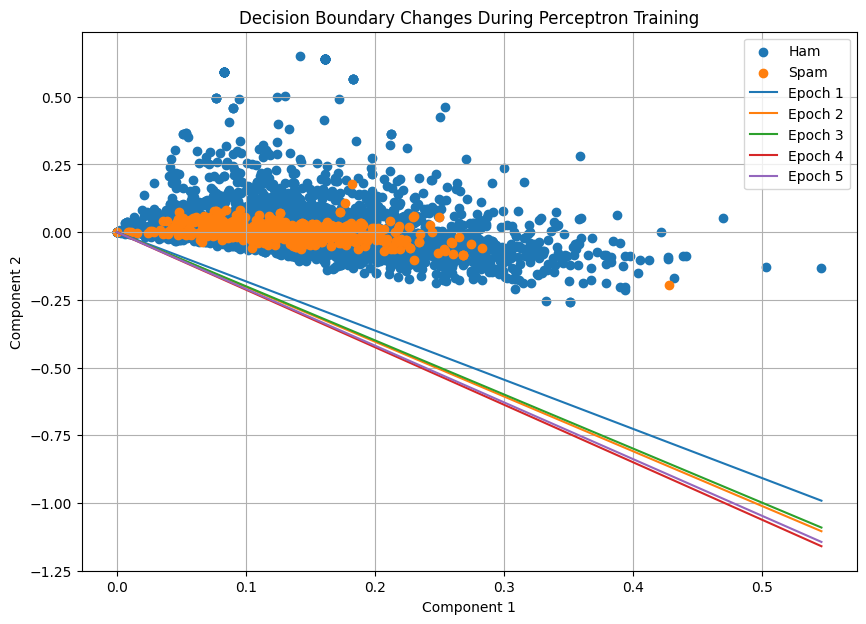

In [24]:
import numpy as np
import matplotlib.pyplot as plt
X = X_2D
y = np.where(y_train == 'spam', 1, 0)
weights = np.zeros(2)
bias = 0
learning_rate = 0.1
epochs = 5
boundaries = []
for epoch in range(1, epochs + 1):
    errors = 0
    for i in range(len(X)):
        z = np.dot(X[i], weights) + bias
        prediction = 1 if z >= 0 else 0
        if prediction != y[i]:
            errors += 1
            weights = weights + learning_rate * (
                y[i] - prediction
            ) * X[i]

            bias = bias + learning_rate * (
                y[i] - prediction
            )
    boundaries.append((weights.copy(), bias))
plt.figure(figsize=(10, 7))
plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    label="Ham"
)
plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    label="Spam"
)
x_values = np.linspace(
    X[:, 0].min(),
    X[:, 0].max(),
    100
)
for epoch, (w, b) in enumerate(boundaries, 1):
    if w[1] != 0:
        y_values = -(w[0] * x_values + b) / w[1]
        plt.plot(
            x_values,
            y_values,
            label=f"Epoch {epoch}"
        )
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.title("Decision Boundary Changes During Perceptron Training")
plt.legend()
plt.grid(True)

plt.show()

In [22]:
if prediction != y[i]:
    errors += 1

Epoch: 1
Misclassifications: 1032
Weights: [-0.39468287 -0.21742515]
Bias: 0.0


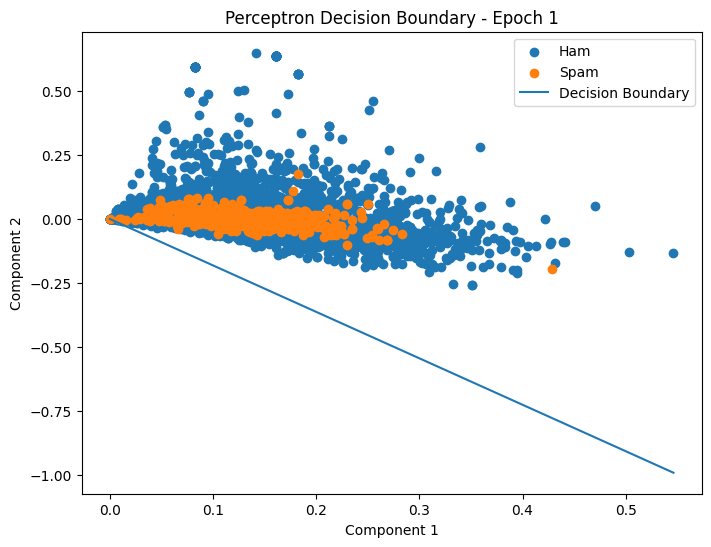

Epoch: 2
Misclassifications: 1030
Weights: [-0.41589557 -0.20572058]
Bias: 0.0


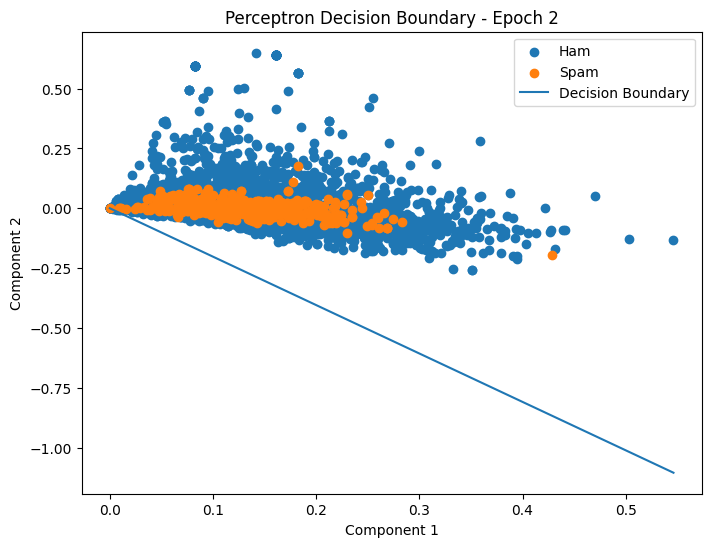

Epoch: 3
Misclassifications: 1030
Weights: [-0.41453927 -0.20759982]
Bias: 0.0


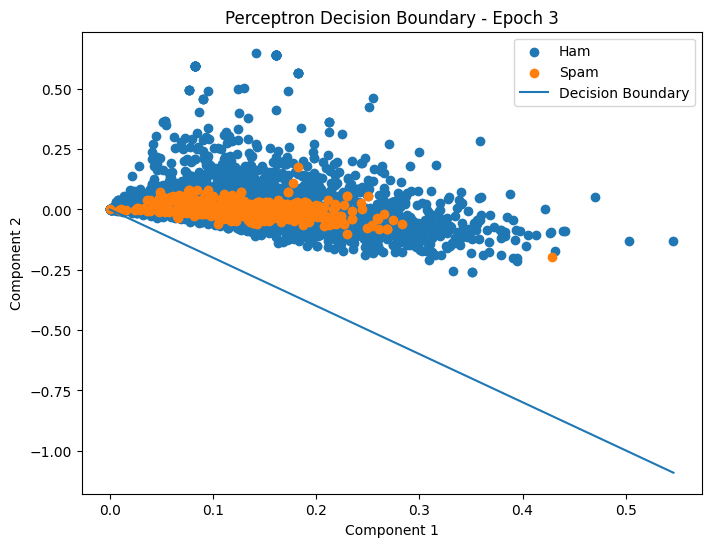

Epoch: 4
Misclassifications: 1030
Weights: [-0.42508595 -0.20022406]
Bias: 0.0


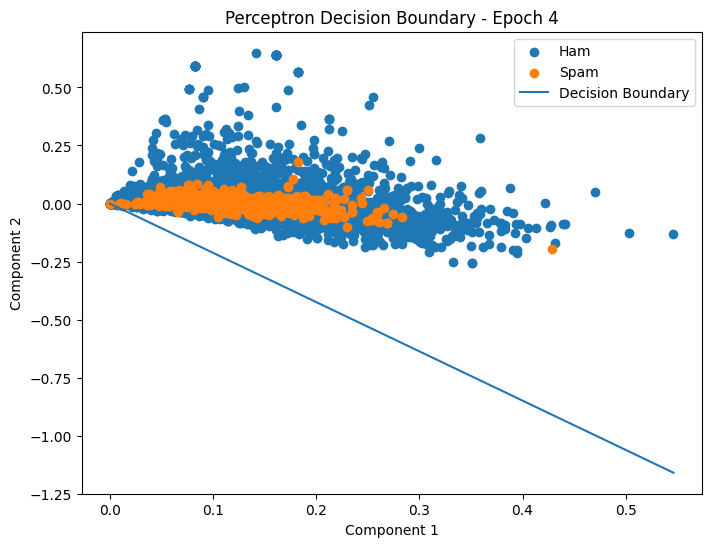

Epoch: 5
Misclassifications: 1030
Weights: [-0.41838148 -0.19979898]
Bias: 0.0


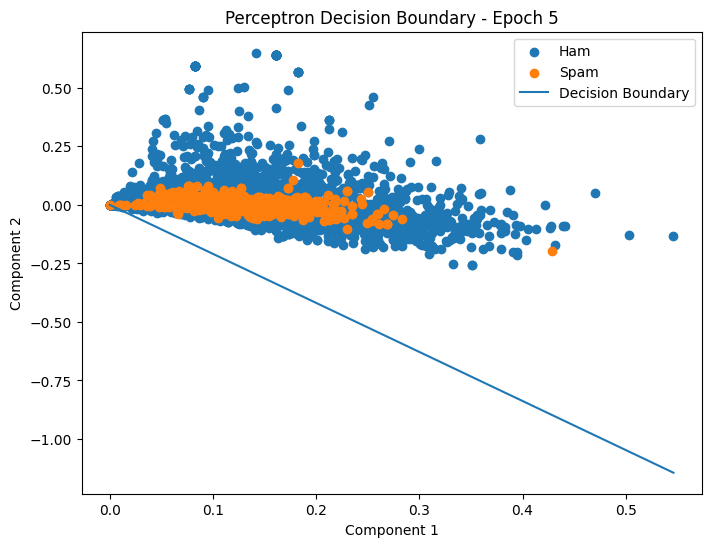

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
X = X_2D
y = np.where(y_train == 'spam', 1, 0)
weights = np.zeros(2)
bias = 0
learning_rate = 0.1
epochs = 5
misclassifications = []
def plot_boundary(X, y, weights, bias, epoch):
    plt.figure(figsize=(8, 6))
    plt.scatter(
        X[y == 0, 0],
        X[y == 0, 1],
        label="Ham"
    )
    plt.scatter(
        X[y == 1, 0],
        X[y == 1, 1],
        label="Spam"
    )
    if weights[1] != 0:
        x_values = np.linspace(
            X[:, 0].min(),
            X[:, 0].max(),
            100
        )
        y_values = (
            -(weights[0] * x_values + bias)
            / weights[1]
        )
        plt.plot(
            x_values,
            y_values,
            label="Decision Boundary"
        )
    plt.xlabel("Component 1")
    plt.ylabel("Component 2")
    plt.title(f"Perceptron Decision Boundary - Epoch {epoch}")
    plt.legend()
    plt.show()
for epoch in range(1, epochs + 1):
    errors = 0
    for i in range(len(X)):
        z = np.dot(X[i], weights) + bias
        prediction = 1 if z >= 0 else 0
        if prediction != y[i]:
            errors += 1
            weights = weights + learning_rate * (
                y[i] - prediction
            ) * X[i]
            bias = bias + learning_rate * (
                y[i] - prediction
            )
    misclassifications.append(errors)
    print("Epoch:", epoch)
    print("Misclassifications:", errors)
    print("Weights:", weights)
    print("Bias:", bias)
    plot_boundary(X, y, weights, bias, epoch)

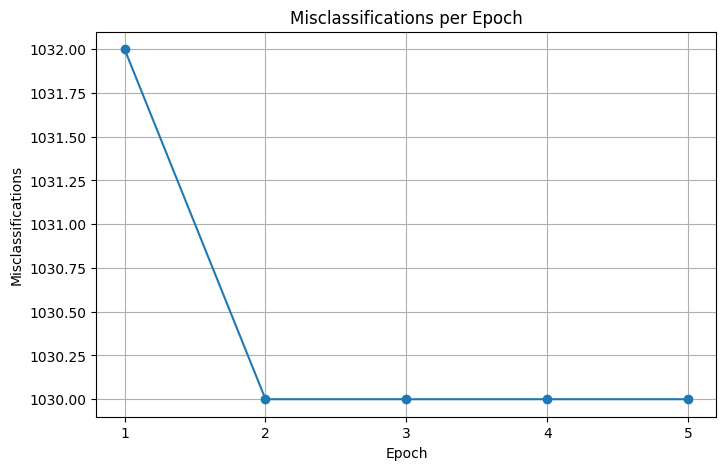

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    misclassifications,
    marker='o'
)
plt.xlabel("Epoch")
plt.ylabel("Misclassifications")
plt.title("Misclassifications per Epoch")
plt.xticks(range(1, epochs + 1))
plt.grid(True)
plt.show()